### **K-means vs Random Initialization**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src.distributions import LCG, uniform, gaussian
from src.gmm import GMM
from src.kmeans import KMeans

### **Experiment-only GMM Copy**


In [2]:
class GMM:
    def __init__(self, K=3, reg=1e-6, max_iter=100, tol=1e-6,
                 init="kmeans", seed=42):
        self.K = K
        self.reg = reg
        self.max_iter = max_iter
        self.tol = tol
        self.init = init
        self.seed = seed
        self.weights = None
        self.means = None
        self.covariances = None
        self.log_likelihoods = []

    def component_scores(self, X):
        n, d = X.shape
        scores = np.zeros((n, self.K))

        for k in range(self.K):
            difference = X - self.means[k]
            eigenvalues = np.linalg.eigvalsh(self.covariances[k])
            if np.any(eigenvalues <= 0):
                raise ValueError("Covariance must be positive definite. Try a larger reg.")
            # Log determinant = sum of the logs of the eigenvalues.
            log_det = np.log(eigenvalues).sum()
            inverse_covariance = np.linalg.inv(self.covariances[k])
            # Quadratic term: (x - mean).T @ inverse_covariance @ (x - mean)
            d_squared = np.sum((difference @ inverse_covariance) * difference, axis=1)
            scores[:, k] = np.log(self.weights[k]) - 0.5 * (
                d * np.log(2 * np.pi) + log_det + d_squared
            )

        return scores

    def score_samples(self, X):
        # log of the mixture density, calculated without tiny exponentials
        scores = self.component_scores(X)
        largest = scores.max(axis=1)
        return largest + np.log(np.exp(scores - largest[:, None]).sum(axis=1))

    def fit(self, X):
        n, d = X.shape
        self.log_likelihoods = []

        if self.init == "kmeans":
            model = KMeans(K=self.K)
            model.fit(X)
            labels = model.predict(X)

            self.means = model.centers.copy()
            self.weights = np.zeros(self.K)
            self.covariances = np.zeros((self.K, d, d))

            for k in range(self.K):
                points = X[labels == k]
                if len(points) == 0:
                    raise ValueError("K-means produced an empty component. Try another K.")
                difference = points - self.means[k]
                self.weights[k] = len(points) / n
                self.covariances[k] = difference.T @ difference / len(points)
                self.covariances[k] += self.reg * np.eye(d)
        elif self.init == "random":
            rng = np.random.default_rng(self.seed)
            indices = rng.choice(n, size=self.K, replace=False)
            self.means = X[indices].copy()
            self.weights = np.full(self.K, 1.0 / self.K)
            difference = X - X.mean(axis=0)
            covariance = difference.T @ difference / n
            covariance += self.reg * np.eye(d)
            self.covariances = np.array([covariance.copy() for _ in range(self.K)])
        else:
            raise ValueError("init must be 'kmeans' or 'random'.")

        for _ in range(self.max_iter):
            # E-step: soft membership of each point in each component
            scores = self.component_scores(X)
            scores -= scores.max(axis=1, keepdims=True)
            responsibilities = np.exp(scores)
            responsibilities /= responsibilities.sum(axis=1, keepdims=True)

            # M-step: update weights, means, and covariances
            counts = responsibilities.sum(axis=0)
            if np.any(counts < 1e-10):
                raise ValueError("A component has no effective points. Try a smaller K.")
            self.weights = counts / n
            self.means = responsibilities.T @ X / counts[:, None]

            for k in range(self.K):
                difference = X - self.means[k]
                weighted_difference = responsibilities[:, k, None] * difference
                self.covariances[k] = difference.T @ weighted_difference / counts[k]
                self.covariances[k] += self.reg * np.eye(d)

            log_likelihood = self.score_samples(X).mean()
            self.log_likelihoods.append(log_likelihood)
            if len(self.log_likelihoods) > 1:
                change = self.log_likelihoods[-1] - self.log_likelihoods[-2]
                if abs(change) < self.tol:
                    break

        return self


In [3]:
n = 5000
K = 3
weights = np.array([0.5, 0.3, 0.2])

means = np.array([[-1.0, -3.5], [0.0, 0.0], [1.0, 3.5]])
means_2 = means + np.array([7.0, 0.0])
class_means = [means, means_2]

covariances = [
    np.array([[1.0, 0.6], [0.6, 1.0]]),  # bottom: full
    np.eye(2),                           # middle: isotropic
    np.diag([1.5, 0.5])                  # top: diagonal
]

covariances_2 = [
    np.array([[1.0, -0.6], [-0.6, 1.0]]),
    np.eye(2),
    np.array([[1.5, -0.5], [-0.5, 0.5]])
]
class_covariances = [covariances, covariances_2]
covariance_names = [
    ["Full (+tilt)", "Isotropic", "Diagonal"],
    ["Full (-tilt)", "Isotropic", "Full (-tilt)"]
]

In [4]:
# GMM data generation - 2 GMMs each has 3 gaussian components.

class_samples = []
class_component_labels = []

for class_index in range(2):
    rng = LCG(42 + class_index)
    labels = np.zeros(n, dtype=int)
    for i in range(n):
        u = uniform(0, 1, 1, rng)[0]
        if u < weights[0]:
            labels[i] = 0
        elif u < weights[0] + weights[1]:
            labels[i] = 1
        else:
            labels[i] = 2

    X = np.zeros((n, 2))

    for k in range(K):
        selected = labels == k
        component_n = np.sum(selected)

        eigenvalues, eigenvectors = np.linalg.eigh(class_covariances[class_index][k])
        cov_sqrt = eigenvectors @ np.diag(np.sqrt(eigenvalues)) @ eigenvectors.T

        standard_samples = np.column_stack((
            gaussian(0, 1, component_n, rng),
            gaussian(0, 1, component_n, rng)
        ))
        X[selected] = standard_samples @ cov_sqrt.T + class_means[class_index][k]

    class_samples.append(X)
    class_component_labels.append(labels)

print([sample.shape for sample in class_samples])
print([labels.shape for labels in class_component_labels])

[(5000, 2), (5000, 2)]
[(5000,), (5000,)]


In [5]:
# train and test split - 80% train and 20% test

train_class_samples = []
test_class_samples = []

rng = np.random.default_rng(44)
train_end = int(0.8 * n)

for samples in class_samples:
    shuffled = samples[rng.permutation(n)]
    train_class_samples.append(shuffled[:train_end])
    test_class_samples.append(shuffled[train_end:])

### **Compare Average Training Log-Likelihood**


In [6]:
seed = 42
results = []

for samples in train_class_samples:
    runs = []
    model = GMM(K=3, max_iter=300, tol=1e-6)
    model.fit(samples)
    runs.append(("K-means", model))

    model = GMM(K=3, max_iter=300, tol=1e-6, init="random", seed=seed)
    model.fit(samples)
    runs.append(("Random (seed 42)", model))

    results.append(runs)

for class_index, runs in enumerate(results):
    print(f"Class {class_index + 1}")
    for name, model in runs:
        print(f"{name:12s} iterations={len(model.log_likelihoods):3d} "
              f"final average log-likelihood={model.log_likelihoods[-1]:.8f}")
        if len(model.log_likelihoods) == model.max_iter:
            print("  Iteration limit reached.")
    print()


Class 1
K-means      iterations= 29 final average log-likelihood=-3.59340419
Random (seed 42) iterations= 48 final average log-likelihood=-3.59340431

Class 2
K-means      iterations= 10 final average log-likelihood=-3.63638859
Random (seed 42) iterations= 29 final average log-likelihood=-3.63638826



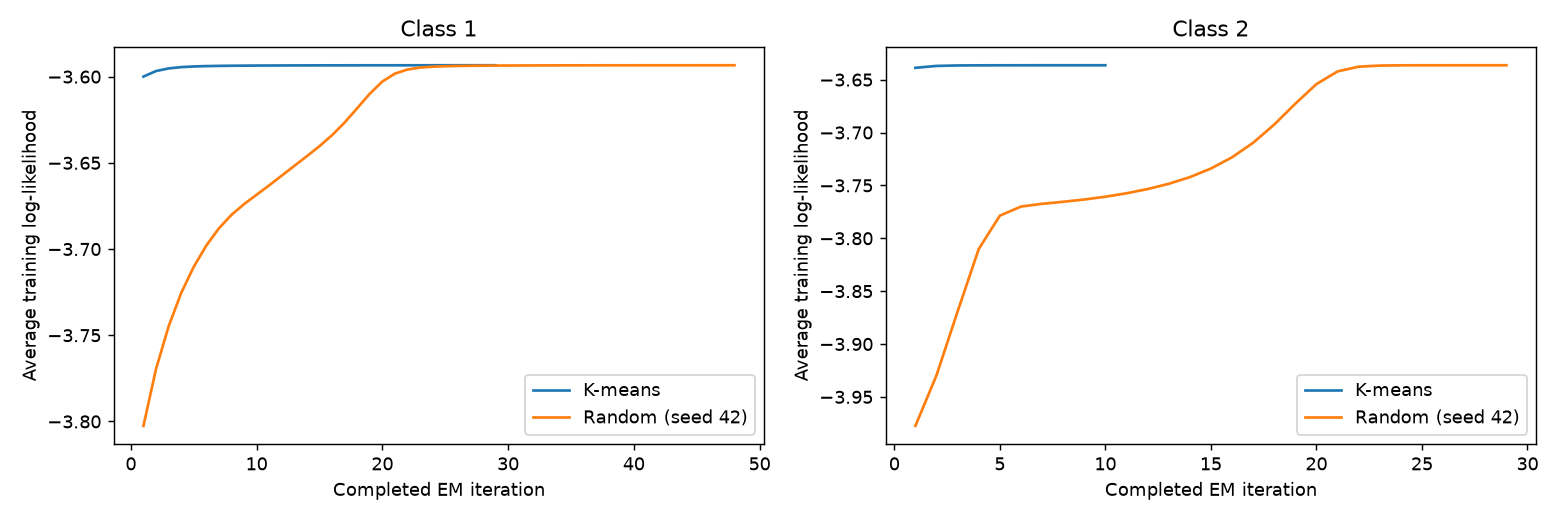

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for class_index, runs in enumerate(results):
    for name, model in runs:
        iterations = np.arange(1, len(model.log_likelihoods) + 1)
        axes[class_index].plot(iterations, model.log_likelihoods, label=name)
    axes[class_index].set_title(f"Class {class_index + 1}")
    axes[class_index].set_xlabel("Completed EM iteration")
    axes[class_index].set_ylabel("Average training log-likelihood")
    axes[class_index].legend()
fig.tight_layout()
plt.show()


### **MNIST: 2D PCA**


In [8]:
import os
from PIL import Image

digits = np.array([2, 3, 9])


def load_digit_images(folder):
    class_images = []
    for digit in digits:
        images = []
        digit_folder = f"{folder}/{digit}"
        for filename in sorted(os.listdir(digit_folder)):
            if filename.endswith(".png"):
                with Image.open(f"{digit_folder}/{filename}") as image:
                    images.append(np.array(image.convert("L")))
        class_images.append(np.array(images, dtype=float) / 255.0)
    return class_images


mnist_train_images = load_digit_images("./data/train")
mnist_dev_images = load_digit_images("./data/dev")

for digit, train_images, dev_images in zip(digits, mnist_train_images, mnist_dev_images):
    print(f"Digit {digit}: train {train_images.shape}, dev {dev_images.shape}")

Digit 2: train (4762, 28, 28), dev (1196, 28, 28)
Digit 3: train (4886, 28, 28), dev (1245, 28, 28)
Digit 9: train (4776, 28, 28), dev (1173, 28, 28)


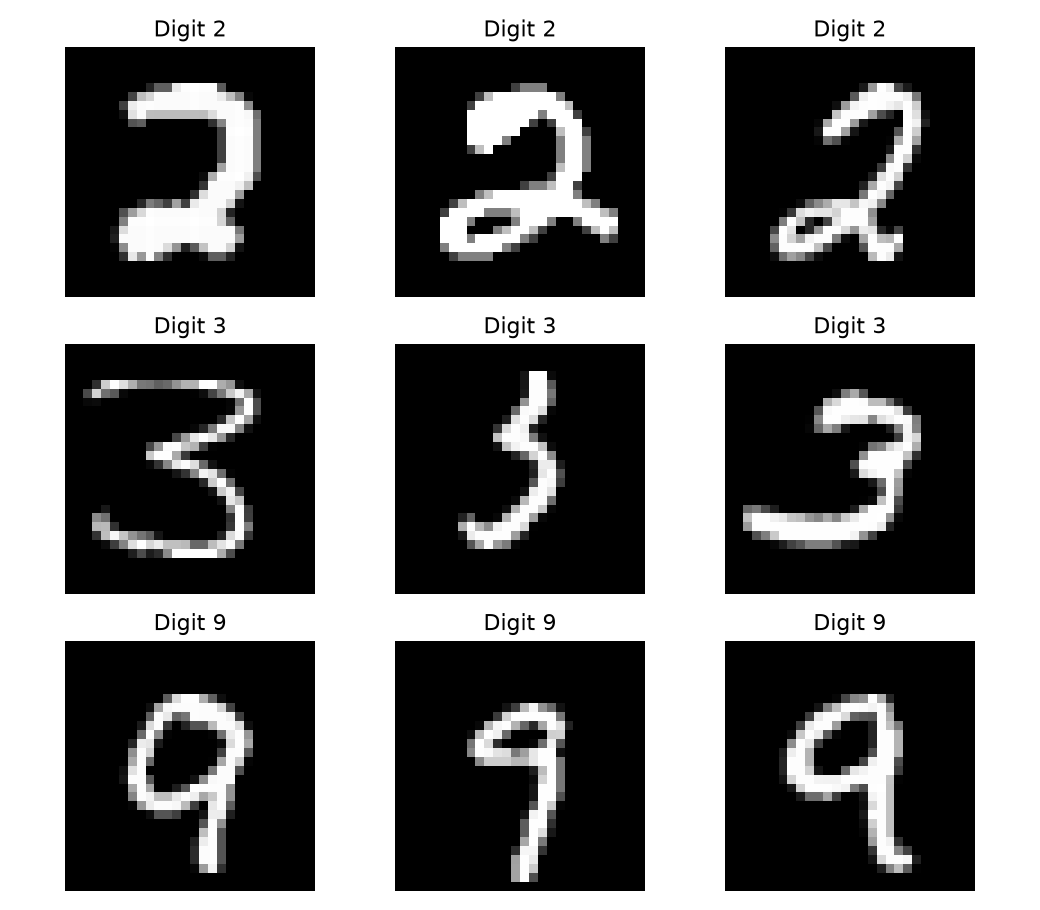

In [9]:
def pixel_features(images):
    return images.reshape(len(images), 784)


mnist_train = [pixel_features(images) for images in mnist_train_images]
mnist_dev = [pixel_features(images) for images in mnist_dev_images]

plt.figure(figsize=(8, 7))
for class_index, digit in enumerate(digits):
    for i in range(3):
        plt.subplot(3, 3, class_index * 3 + i + 1)
        plt.imshow(mnist_train_images[class_index][i], cmap="gray", vmin=0, vmax=1)
        plt.title(f"Digit {digit}")
        plt.axis("off")

plt.tight_layout()
plt.show()

### **Fit PCA Using Training Images Only**


In [10]:
all_train = np.vstack(mnist_train)
pca_mean = all_train.mean(axis=0)
centered_train = all_train - pca_mean

# PCA directions: eigenvectors with the two largest covariance eigenvalues.
pixel_covariance = centered_train.T @ centered_train / (len(all_train) - 1)
eigenvalues, eigenvectors = np.linalg.eigh(pixel_covariance)
pca_components = eigenvectors[:, -2:][:, ::-1]
explained_variance = eigenvalues[-2:][::-1] / eigenvalues.sum()

mnist_train_2d = [(samples - pca_mean) @ pca_components for samples in mnist_train]
mnist_dev_2d = [(samples - pca_mean) @ pca_components for samples in mnist_dev]

print("PCA feature count:", pca_components.shape[1])
print("Variance retained by PC1 and PC2:", explained_variance)
print(f"Total variance retained: {explained_variance.sum():.2%}")


PCA feature count: 2
Variance retained by PC1 and PC2: [0.11504586 0.10270948]
Total variance retained: 21.78%


### **Fit Eight Gaussian Components per Digit**


In [ ]:
# Match the original MNIST experiment: fix K=8 rather than reselecting it.
pca_best_K = 8
pca_models = []

for digit, samples in zip(digits, mnist_train_2d):
    model = GMM(K=pca_best_K, reg=1e-6, max_iter=1000, tol=1e-5)
    model.fit(samples)
    pca_models.append(model)
    print(f"Digit {digit}: {len(model.log_likelihoods)} EM iterations")
    if len(model.log_likelihoods) == model.max_iter:
        print("  Iteration limit reached.")

correct = 0
total = 0
for true_class, samples in enumerate(mnist_dev_2d):
    scores = np.column_stack([model.score_samples(samples) for model in pca_models])
    predictions = np.argmax(scores, axis=1)
    correct += np.sum(predictions == true_class)
    total += len(samples)
print(f"K=8 development accuracy: {correct / total:.2%}")

Digit 2: 120 EM iterations
Digit 3: 54 EM iterations
Digit 9: 325 EM iterations
K=8 development accuracy: 86.30%


### **2D PCA Test Results**


In [12]:
# Test images are used only after PCA and component selection are fixed.
pca_test_images = load_digit_images("./data/test")
pca_test = [pixel_features(images) for images in pca_test_images]
mnist_test_2d = [(samples - pca_mean) @ pca_components for samples in pca_test]
pca_confusion = np.zeros((3, 3), dtype=int)
pca_predictions = []

for true_class, samples in enumerate(mnist_test_2d):
    scores = np.column_stack([model.score_samples(samples) for model in pca_models])
    predictions = np.argmax(scores, axis=1)
    pca_predictions.append(predictions)
    for predicted_class in predictions:
        pca_confusion[true_class, predicted_class] += 1

print("Digit order:", digits)
print("Confusion matrix (rows: actual, columns: predicted):")
print(pca_confusion)
pca_test_accuracy = np.trace(pca_confusion) / pca_confusion.sum()
print(f"2D PCA test accuracy: {pca_test_accuracy:.2%}")


Digit order: [2 3 9]
Confusion matrix (rows: actual, columns: predicted):
[[866 122  44]
 [114 867  29]
 [ 35  27 947]]
2D PCA test accuracy: 87.84%


### **Decision Regions in 2D PCA Space**


Test points outside the displayed range: 4


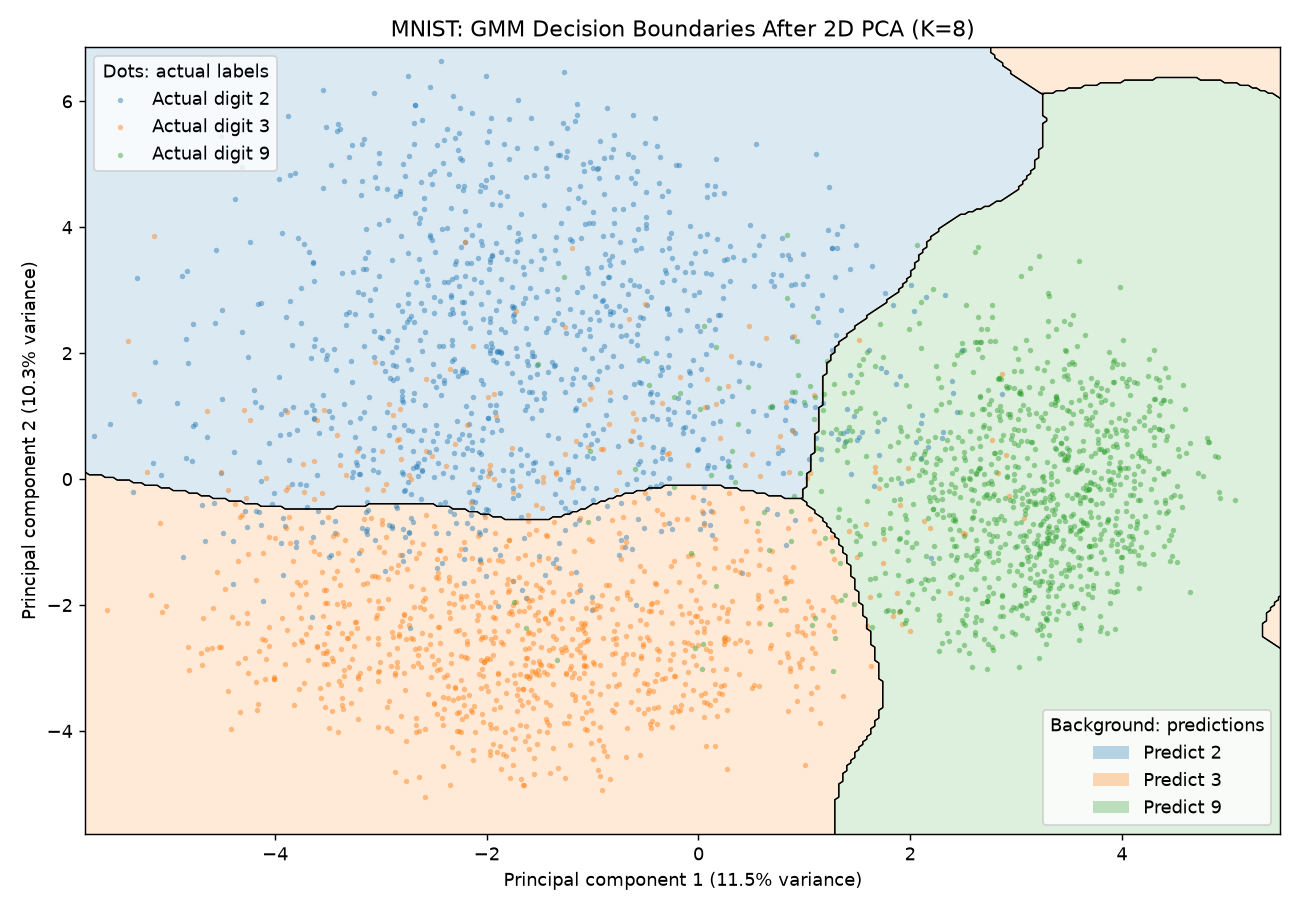

In [13]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Plot the central training range; report any test points outside the view.
all_train_2d = np.vstack(mnist_train_2d)
lower, upper = np.percentile(all_train_2d, [0.5, 99.5], axis=0)
padding = 0.1 * (upper - lower)
lower -= padding
upper += padding

x_values = np.linspace(lower[0], upper[0], 300)
y_values = np.linspace(lower[1], upper[1], 300)
x_grid, y_grid = np.meshgrid(x_values, y_values)
grid_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))
grid_scores = np.column_stack([model.score_samples(grid_points) for model in pca_models])
regions = np.argmax(grid_scores, axis=1).reshape(x_grid.shape)

colors = ["tab:blue", "tab:orange", "tab:green"]
fig, ax = plt.subplots(figsize=(10, 7))
ax.contourf(x_grid, y_grid, regions, levels=[-0.5, 0.5, 1.5, 2.5],
            cmap=ListedColormap(colors), alpha=0.16)
for class_index in range(3):
    mask = (regions == class_index).astype(float)
    if mask.min() != mask.max():
        ax.contour(x_grid, y_grid, mask, levels=[0.5], colors="black", linewidths=0.7)

outside = 0
for class_index, samples in enumerate(mnist_test_2d):
    ax.scatter(samples[:, 0], samples[:, 1], s=9, alpha=0.45, linewidths=0,
               color=colors[class_index], label=f"Actual digit {digits[class_index]}")
    outside += np.sum(np.any((samples < lower) | (samples > upper), axis=1))

point_legend = ax.legend(loc="upper left", title="Dots: actual labels")
ax.add_artist(point_legend)
ax.legend(handles=[Patch(facecolor=colors[i], alpha=0.3, label=f"Predict {digit}")
                   for i, digit in enumerate(digits)],
          loc="lower right", title="Background: predictions")
ax.set_xlim(lower[0], upper[0])
ax.set_ylim(lower[1], upper[1])
ax.set_xlabel(f"Principal component 1 ({explained_variance[0]:.1%} variance)")
ax.set_ylabel(f"Principal component 2 ({explained_variance[1]:.1%} variance)")
ax.set_title(f"MNIST: GMM Decision Boundaries After 2D PCA (K={pca_best_K})")
fig.tight_layout()
plt.show()
print("Test points outside the displayed range:", outside)


### **Gaussian Components Within Each Digit**


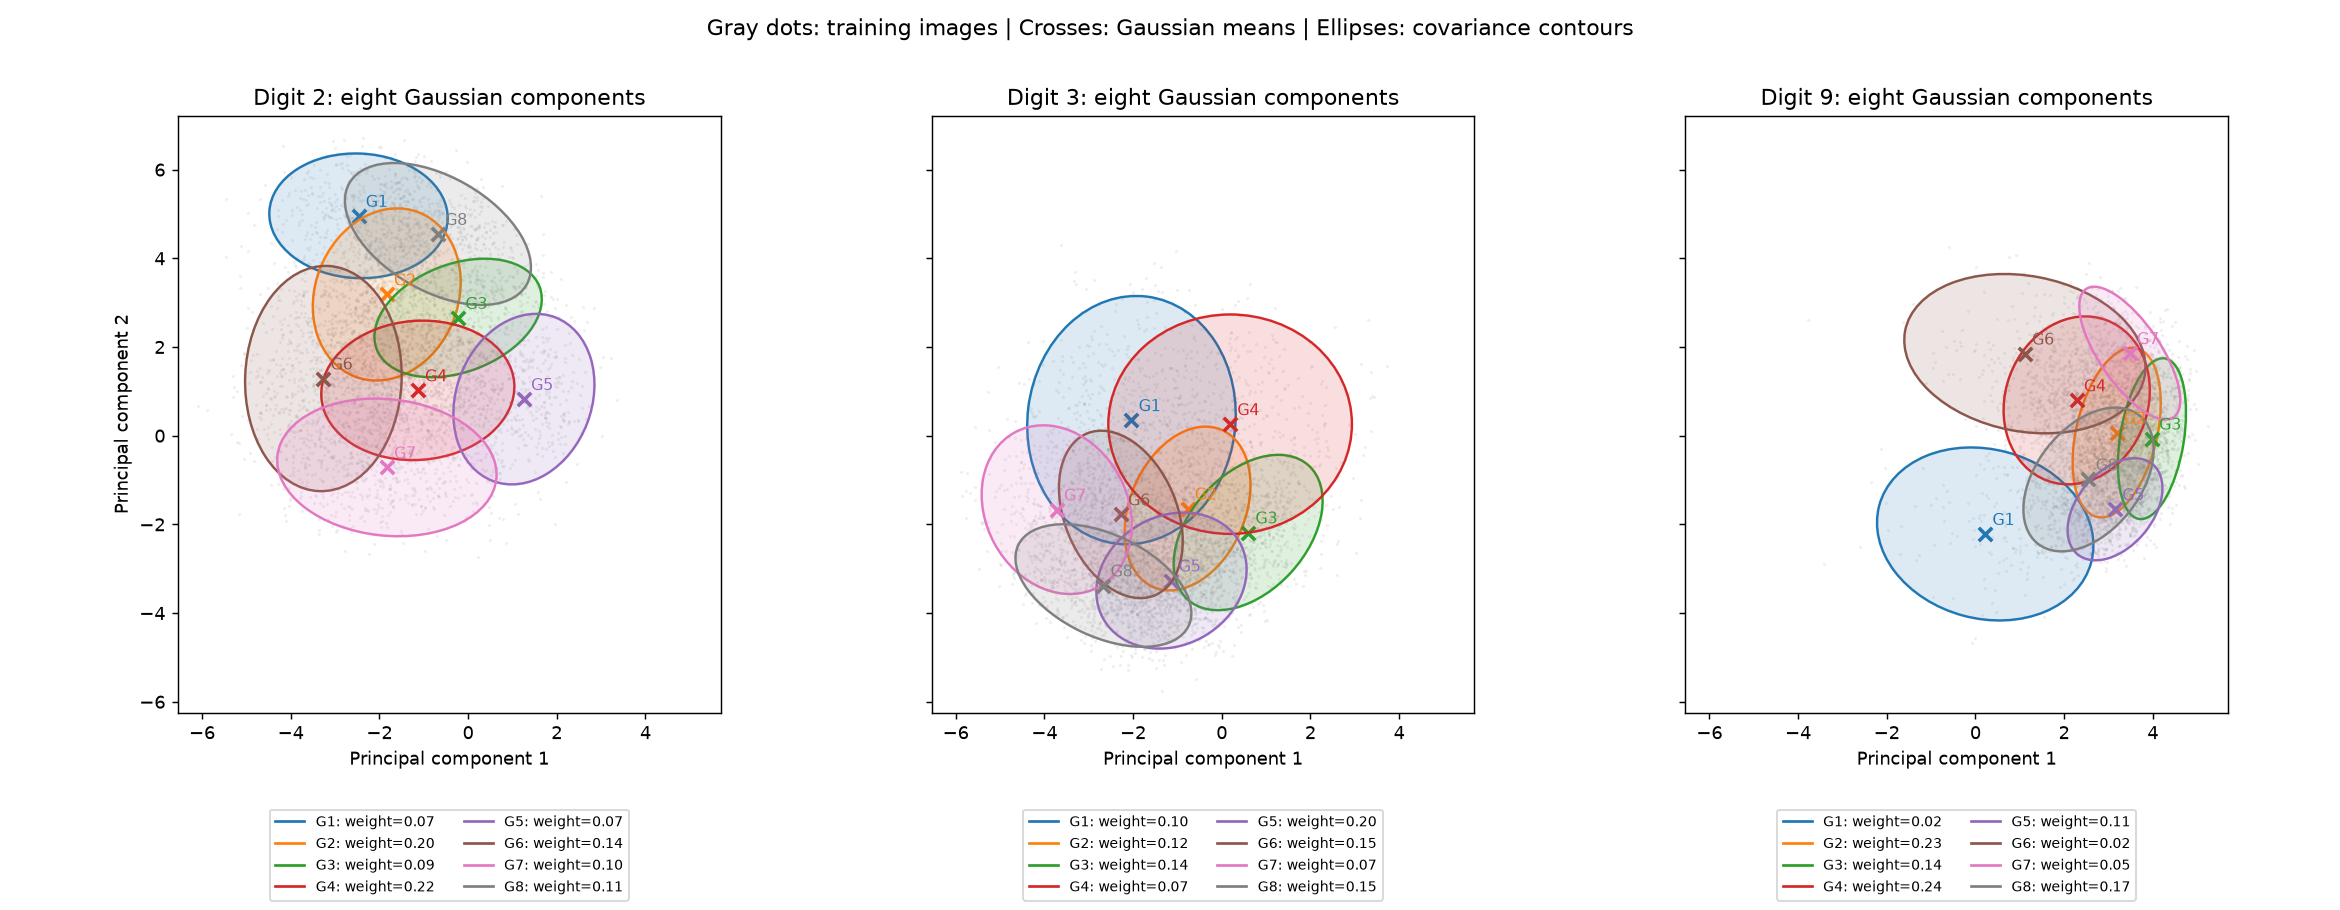

In [14]:
from matplotlib.patches import Ellipse
from matplotlib.lines import Line2D

# Each ellipse has Mahalanobis radius 2; it is not a hard assignment boundary.
component_colors = plt.get_cmap("tab10")
all_points = np.vstack(mnist_train_2d)
lower = np.minimum(all_points.min(axis=0), np.array([m.means.min(axis=0) for m in pca_models]).min(axis=0))
upper = np.maximum(all_points.max(axis=0), np.array([m.means.max(axis=0) for m in pca_models]).max(axis=0))
ellipse_specs = []

for model in pca_models:
    specs = []
    for k in range(model.K):
        values, vectors = np.linalg.eigh(model.covariances[k])
        order = np.argsort(values)[::-1]
        values = values[order]
        vectors = vectors[:, order]
        angle = np.degrees(np.arctan2(vectors[1, 0], vectors[0, 0]))
        width, height = 4 * np.sqrt(values)
        specs.append((width, height, angle))
        # Axis-aligned extent of the radius-2 covariance ellipse.
        extent = 2 * np.sqrt(np.diag(model.covariances[k]))
        lower = np.minimum(lower, model.means[k] - extent)
        upper = np.maximum(upper, model.means[k] + extent)
    ellipse_specs.append(specs)

padding = 0.04 * (upper - lower)
fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharex=True, sharey=True)
for class_index, (digit, samples, model) in enumerate(zip(digits, mnist_train_2d, pca_models)):
    ax = axes[class_index]
    ax.scatter(samples[:, 0], samples[:, 1], s=3, color="gray", alpha=0.12, linewidths=0)
    legend = []
    for k, (width, height, angle) in enumerate(ellipse_specs[class_index]):
        color = component_colors(k)
        ellipse = Ellipse(model.means[k], width, height, angle=angle,
                          facecolor=color, edgecolor=color, alpha=0.15, linewidth=1.5)
        ax.add_patch(ellipse)
        ax.add_patch(Ellipse(model.means[k], width, height, angle=angle,
                             fill=False, edgecolor=color, linewidth=1.3))
        ax.scatter(*model.means[k], marker="x", s=55, color=color, linewidths=2)
        ax.annotate(f"G{k + 1}", model.means[k], xytext=(4, 5),
                    textcoords="offset points", color=color, fontsize=9)
        legend.append(Line2D([0], [0], color=color,
                             label=f"G{k + 1}: weight={model.weights[k]:.2f}"))
    ax.set_title(f"Digit {digit}: eight Gaussian components")
    ax.set_xlabel("Principal component 1")
    ax.set_xlim(lower[0] - padding[0], upper[0] + padding[0])
    ax.set_ylim(lower[1] - padding[1], upper[1] + padding[1])
    ax.set_aspect("equal", adjustable="box")
    ax.legend(handles=legend, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
axes[0].set_ylabel("Principal component 2")
fig.suptitle("Gray dots: training images | Crosses: Gaussian means | Ellipses: covariance contours")
fig.tight_layout(rect=[0, 0.05, 1, 0.94])
plt.show()
